In [2]:
import cv2
import numpy as np
import pandas as pd
import os
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
import re

import warnings
warnings.filterwarnings("ignore")

In [3]:
def merge_vertical_boxes(boxes):

    if not boxes:
        return []
    
    boxes.sort(key=lambda b: b[0])
    merged = []
    
    current_box = boxes[0]
    for next_box in boxes[1:]:
        cx, cy, cw, ch = current_box
        nx, ny, nw, nh = next_box
        
        if nx <= cx + cw + 5:
            min_x = min(cx, nx)
            min_y = min(cy, ny)
            max_r = max(cx + cw, nx + nw)
            max_b = max(cy + ch, ny + nh)
            
            current_box = [min_x, min_y, max_r - min_x, max_b - min_y]
        else:
            merged.append(current_box)
            current_box = next_box
            
    merged.append(current_box)
    return merged

def extract_characters(image_path, debug=True):
    img = cv2.imread(image_path)

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    
    kernel = np.ones((2,2), np.uint8)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=1)
    
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    boxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if w > 5 and h > 5:
            boxes.append([x, y, w, h])
            
    merged_boxes = merge_vertical_boxes(boxes)
    
    merged_boxes.sort(key=lambda b: b[0])
    
    if debug:
        out_img = img.copy()
        for i, (x, y, w, h) in enumerate(merged_boxes):
            cv2.rectangle(out_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv2.putText(out_img, str(i), (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)
            
        plt.figure(figsize=(10, 4))
        plt.subplot(1, 2, 1)
        plt.title("Original Binary")
        plt.imshow(thresh, cmap='gray')
        plt.subplot(1, 2, 2)
        plt.title("Bounding Boxes")
        plt.imshow(cv2.cvtColor(out_img, cv2.COLOR_BGR2RGB))
        plt.show()
        
    return thresh, merged_boxes

In [4]:
def crop_and_resize_characters(binary_image, bounding_boxes, target_size=(28, 28), padding=4):
    cropped_chars = []
    
    for (x, y, w, h) in bounding_boxes:
        y1 = max(0, y - padding)
        y2 = min(binary_image.shape[0], y + h + padding)
        x1 = max(0, x - padding)
        x2 = min(binary_image.shape[1], x + w + padding)
        
        char_crop = binary_image[y1:y2, x1:x2]
        
        if char_crop.shape[0] == 0 or char_crop.shape[1] == 0:
            continue
            
        max_dim = max(char_crop.shape[0], char_crop.shape[1])
        squared_img = np.zeros((max_dim, max_dim), dtype=np.uint8)
        
        x_offset = (max_dim - char_crop.shape[1]) // 2
        y_offset = (max_dim - char_crop.shape[0]) // 2
        
        squared_img[y_offset:y_offset + char_crop.shape[0], 
                   x_offset:x_offset + char_crop.shape[1]] = char_crop
                   
        resized_char = cv2.resize(squared_img, target_size, interpolation=cv2.INTER_AREA)
        
        cropped_chars.append(resized_char)
        
    return cropped_chars


def save_dataset_for_labeling(cropped_chars, image_id, output_dir="temp_dataset"):

    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
        
    for i, char_img in enumerate(cropped_chars):
        filename = f"{output_dir}/img{image_id}_char{i}.png"
        cv2.imwrite(filename, char_img)


In [5]:

df = pd.read_csv('train_info.csv')
df['type'] = df['type'].astype(str)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(df['type']),
    y=df['type']
)

weight_dict = {0: class_weights[0], 1: class_weights[1]}
print("Class weights:", weight_dict)

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

TRAIN_DIR = 'train/'
IMAGE_SIZE = (64, 64)
BATCH_SIZE = 16

train_generator = datagen.flow_from_dataframe(
    dataframe=df,
    directory=TRAIN_DIR,
    x_col='path',
    y_col='type',
    target_size=IMAGE_SIZE,
    color_mode='grayscale',
    class_mode='binary',
    batch_size=BATCH_SIZE,
    subset='training'
)

val_generator = val_datagen.flow_from_dataframe(
    dataframe=df,
    directory=TRAIN_DIR,
    x_col='path',
    y_col='type',
    target_size=IMAGE_SIZE,
    color_mode='grayscale',
    class_mode='binary',
    batch_size=BATCH_SIZE,
    subset='validation'
)

model = Sequential([
    Conv2D(16, (3, 3), activation='relu', input_shape=(64, 64, 1)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    
    Conv2D(32, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

callbacks = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ModelCheckpoint('best_type_classifier.keras', monitor='val_accuracy', save_best_only=True)
]

history = model.fit(
    train_generator,
    epochs=40,
    validation_data=val_generator,
    class_weight=weight_dict,
    callbacks=callbacks
)

print("Model training completed successfully.")

Class weights: {0: np.float64(0.6157337367624811), 1: np.float64(2.6601307189542482)}
Found 652 validated image filenames belonging to 2 classes.
Found 162 validated image filenames belonging to 2 classes.


I0000 00:00:1789763879.788137 2772610 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4035 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Epoch 1/40


I0000 00:00:1789763880.565518 2772610 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1789763881.638421 2772815 service.cc:153] XLA service 0x78dd04035f60 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1789763881.638445 2772815 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.22.0)
I0000 00:00:1789763881.675101 2772815 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1789763881.892663 2772815 cuda_dnn.cc:461] Loaded cuDNN version 92200
I0000 00:00:1789763881.937022 2772815 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2663__.39


 4/41 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.6628 - loss: 0.7550

I0000 00:00:1789763885.182532 2772815 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1789763885.547920 2772814 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2663__.39


41/41 ━━━━━━━━━━━━━━━━━━━━ 11s 164ms/step - accuracy: 0.9785 - loss: 0.0471 - val_accuracy: 0.8086 - val_loss: 1.0016
Epoch 2/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 1.0000 - loss: 2.5631e-05 - val_accuracy: 0.8086 - val_loss: 0.3120
Epoch 3/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 1.0000 - loss: 1.2749e-06 - val_accuracy: 1.0000 - val_loss: 0.1373
Epoch 4/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 1.0000 - loss: 1.5865e-06 - val_accuracy: 0.4506 - val_loss: 0.8029
Epoch 5/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 1.0000 - loss: 4.3042e-06 - val_accuracy: 0.2160 - val_loss: 1.7291
Epoch 6/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 1.0000 - loss: 1.8155e-04 - val_accuracy: 0.3210 - val_loss: 1.5249
Epoch 7/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 1.0000 - loss: 1.4853e-05 - val_accuracy: 0.5864 - val_loss: 0.9004
Epoch 8/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 1.0000 - loss: 7.3558e-07 - val_a

In [6]:
def extract_number(filename):

    s = re.findall(r'\d+', filename)
    return int(s[0]) if s else -1

model = tf.keras.models.load_model('best_type_classifier.keras')

TEST_DIR = 'test/'
test_images = [f for f in os.listdir(TEST_DIR) if f.endswith('.png')]
test_images.sort(key=extract_number)

predictions = []

for img_name in test_images:
    img_path = os.path.join(TEST_DIR, img_name)
    
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue
        
    img_resized = cv2.resize(img, (64, 64))
    
    img_array = img_resized.astype('float32') / 255.0
    img_array = np.expand_dims(img_array, axis=-1) 
    img_array = np.expand_dims(img_array, axis=0)  
    
    pred_prob = model.predict(img_array, verbose=0)[0][0]
    
    pred_class = 1 if pred_prob > 0.5 else 0
    
    predictions.append({
        'filename': img_name,
        'type': pred_class
    })

df_test_types = pd.DataFrame(predictions)

df_test_types.to_csv('temp_type_predictions.csv', index=False)
df_test_types.head(10)

,filename,type
0,0.png,1
1,1.png,1
2,2.png,0
3,3.png,1
4,4.png,1
5,5.png,0
6,6.png,1
7,7.png,1
8,8.png,1
9,9.png,0


In [7]:
import os
import cv2
import pandas as pd
import glob

# 1. Create a temporary directory
TEMP_DIR = 'temp_dataset/'
if not os.path.exists(TEMP_DIR):
    os.makedirs(TEMP_DIR)

# 2. Read the first 50 images from the training set
df_train = pd.read_csv('train_info.csv')
sample_images = df_train['path'].head(50).tolist()
TRAIN_DIR = 'train/'

char_count = 0
for img_name in sample_images:
    img_path = os.path.join(TRAIN_DIR, img_name)
    try:
        # Extract bounding boxes
        thresh, boxes = extract_characters(img_path, debug=False)
        # Crop and resize (28x28 is standard for OCR)
        chars = crop_and_resize_characters(thresh, boxes, target_size=(28, 28), padding=4)
        
        # Save to the temporary directory
        for i, char_img in enumerate(chars):
            save_path = os.path.join(TEMP_DIR, f"{img_name.split('.')[0]}_char{i}.png")
            cv2.imwrite(save_path, char_img)
            char_count += 1
    except Exception as e:
        print(f"Error on {img_name}: {e}")

print(f"Extracted {char_count} characters and saved them in '{TEMP_DIR}'.")

Extracted 285 characters and saved them in 'temp_dataset/'.


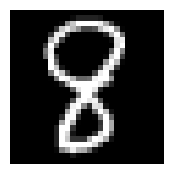

In [8]:
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

DATASET_DIR = "custom_ocr_dataset"
classes = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 
           'plus', 'minus', 'multiply', 'divide', 'l_paren', 'r_paren']

# Create class directories
for c in classes:
    os.makedirs(os.path.join(DATASET_DIR, c), exist_ok=True)

# Get the list of all temporary character images
temp_images = glob.glob(os.path.join(TEMP_DIR, "*.png"))

print("Instructions:")
print("- For digits, type the number (0 to 9).")
print("- For operators: type +, -, *, or /")
print("- For parentheses: type ( or )")
print("- To skip/delete noise: press Space.")
print("- To quit labeling: type q")
print("-" * 40)

for img_path in temp_images:
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    
    # Clear previous output in Jupyter Notebook
    clear_output(wait=True)
    
    # Display the image
    plt.figure(figsize=(2, 2))
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.show()
    
    # Get label from the user
    label_input = input(f"Enter label (Remaining images: {len(temp_images)}): ")
    
    if label_input.lower() == 'q':
        print("Exiting the labeling process.")
        break
        
    # Map user input to folder names
    label_map = {
        '+': 'plus', '=': 'plus',
        '-': 'minus',
        '*': 'multiply', 'x': 'multiply', 'X': 'multiply',
        '/': 'divide', 'd': 'divide',
        '(': 'l_paren', '[': 'l_paren',
        ')': 'r_paren', ']': 'r_paren'
    }
    
    mapped_label = None
    if label_input in [str(i) for i in range(10)]:
        mapped_label = label_input
    elif label_input in label_map:
        mapped_label = label_map[label_input]
    elif label_input == ' ':
        # Remove temporary image (noise)
        os.remove(img_path)
        continue
    
    if mapped_label:
        # Save the image in the final folder and remove from temp folder
        filename = os.path.basename(img_path)
        save_path = os.path.join(DATASET_DIR, mapped_label, filename)
        cv2.imwrite(save_path, img)
        os.remove(img_path)
    else:
        print("Invalid input. Image skipped and kept in temp folder.")

In [10]:
# Define paths and parameters
DATASET_DIR = 'custom_ocr_dataset/'
IMAGE_SIZE = (28, 28)
BATCH_SIZE = 16

# 1. Setup Data Generator with Augmentation for the small dataset
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2, # Use 20% of labeled data for validation
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)

# Load training data
train_generator = datagen.flow_from_directory(
    DATASET_DIR,
    target_size=IMAGE_SIZE,
    color_mode='grayscale',
    class_mode='categorical', # Categorical because we have 16 classes
    batch_size=BATCH_SIZE,
    subset='training'
)

# Load validation data
val_generator = datagen.flow_from_directory(
    DATASET_DIR,
    target_size=IMAGE_SIZE,
    color_mode='grayscale',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    subset='validation'
)

# Get number of classes and print the class mapping
class_indices = train_generator.class_indices
num_classes = len(class_indices)
print("Class mapping:", class_indices)

# 2. Build the OCR CNN Model
ocr_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') # Softmax for multi-class classification
])

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
ocr_model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ModelCheckpoint('best_ocr_model.keras', monitor='val_accuracy', save_best_only=True)
]

# 3. Train the model
print("Starting OCR model training...")
history = ocr_model.fit(
    train_generator,
    epochs=50,
    validation_data=val_generator,
    callbacks=callbacks
)

print("OCR Model training completed and saved as 'best_ocr_model.keras'.")

Found 221 images belonging to 16 classes.
Found 45 images belonging to 16 classes.
Class mapping: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9, 'divide': 10, 'l_paren': 11, 'minus': 12, 'multiply': 13, 'plus': 14, 'r_paren': 15}
Starting OCR model training...
Epoch 1/50


I0000 00:00:1789764448.841149 2772814 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_28339__.47


 1/14 ━━━━━━━━━━━━━━━━━━━━ 1:06 5s/step - accuracy: 0.1875 - loss: 3.7252

I0000 00:00:1789764452.792648 2772815 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_28339__.47


14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 445ms/step - accuracy: 0.2896 - loss: 3.3308 - val_accuracy: 0.5111 - val_loss: 2.6560
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5204 - loss: 1.7479 - val_accuracy: 0.3333 - val_loss: 2.5448
Epoch 3/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5566 - loss: 1.4070 - val_accuracy: 0.2000 - val_loss: 2.4929
Epoch 4/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6652 - loss: 1.0401 - val_accuracy: 0.1556 - val_loss: 2.5434
Epoch 5/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7149 - loss: 0.9841 - val_accuracy: 0.1556 - val_loss: 2.7296
Epoch 6/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7330 - loss: 0.8655 - val_accuracy: 0.1556 - val_loss: 2.8772
Epoch 7/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7104 - loss: 0.8956 - val_accuracy: 0.1556 - val_loss: 3.2073
Epoch 8/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8145 - loss: 0.6288 - val_accuracy: 0.1556 - val_loss: 

In [11]:
# 1. Load the trained OCR model
ocr_model = tf.keras.models.load_model('best_ocr_model.keras')

# 2. Create a dictionary to map class indices to characters
# Keras sorts classes alphabetically based on folder names
DATASET_DIR = 'custom_ocr_dataset/'
# Get only directory names (to avoid conflicts with hidden files like .DS_Store)
class_names = sorted([d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))])

label_to_char = {}
for i, class_name in enumerate(class_names):
    if class_name == 'plus': label_to_char[i] = '+'
    elif class_name == 'minus': label_to_char[i] = '-'
    elif class_name == 'multiply': label_to_char[i] = '*'
    elif class_name == 'divide': label_to_char[i] = '/'
    elif class_name == 'l_paren': label_to_char[i] = '('
    elif class_name == 'r_paren': label_to_char[i] = ')'
    else: label_to_char[i] = class_name  # Digits 0 to 9

def evaluate_math_expression(chars_list):
    """Convert character list to a math expression and evaluate it"""
    expr = "".join(chars_list)
    try:
        # Python's eval function evaluates the string expression
        result = eval(expr)
        return float(result)
    except Exception as e:
        # If an error occurs (e.g., consecutive operators or division by zero), 
        # return 0.00 to prevent the program from crashing
        return 0.00

def extract_number(filename):
    """Sort filenames numerically (e.g., 2 from 2.png)"""
    s = re.findall(r'\d+', filename)
    return int(s[0]) if s else -1

TEST_DIR = 'test/'
test_images = [f for f in os.listdir(TEST_DIR) if f.endswith('.png')]
test_images.sort(key=extract_number)

# 3. Load text types (0 or 1) calculated in the previous phase
df_types = pd.read_csv('temp_type_predictions.csv')
type_dict = dict(zip(df_types['filename'], df_types['type']))

results = []

print("Processing test images and evaluating math expressions...")

for img_name in test_images:
    img_path = os.path.join(TEST_DIR, img_name)
    
    # Get the handwriting type (default to 0 if not found)
    img_type = type_dict.get(img_name, 0)
    
    try:
        # Extract and crop characters
        thresh, boxes = extract_characters(img_path, debug=False)
        chars = crop_and_resize_characters(thresh, boxes, target_size=(28, 28), padding=4)
        
        expr_chars = []
        for char_img in chars:
            # Prepare character image for the neural network
            img_array = char_img.astype('float32') / 255.0
            img_array = np.expand_dims(img_array, axis=-1)
            img_array = np.expand_dims(img_array, axis=0)
            
            # Predict character
            pred = ocr_model.predict(img_array, verbose=0)
            class_idx = np.argmax(pred)
            expr_chars.append(label_to_char[class_idx])
            
        # Evaluate the math expression
        ans = evaluate_math_expression(expr_chars)
    except Exception as e:
        # In case of any error in bounding box extraction
        ans = 0.00
        
    # Save the result formatted to exactly two decimal places
    results.append({
        'type': img_type,
        'answer': f"{ans:.2f}"
    })

# 4. Save the final submission file
df_submission = pd.DataFrame(results)
df_submission.to_csv('submission.csv', index=False)

print("Congratulations! 'submission.csv' has been created successfully.")
print(df_submission.head(10))

Processing test images and evaluating math expressions...
Congratulations! 'submission.csv' has been created successfully.
   type     answer
0     1       0.00
1     1     682.00
2     0    2695.00
3     1       0.00
4     1       0.00
5     0       0.00
6     1       0.00
7     1       0.00
8     1  464772.00
9     0      33.00
